# Importing

In [1]:
# %% Cell 1: Imports
import pandas as pd
import numpy as np
from darts import TimeSeries

seed = 24775456

import matplotlib.pyplot as plt
import datetime as dt

# Load Data 

In [5]:
# %% Cell 2: Load Data
def loadData():
    df = pd.read_parquet("gafanha.parquet")
    df["timestamp"] = pd.to_datetime(df["timestamp"]).dt.round("h")
    return (
        df.pivot_table(index="timestamp", columns="collection", values="value", aggfunc="median")
        .asfreq("h")
        .loc[:"2023-12-31 23:00"]
        .drop(columns=["Radiation", "Precipitation"])  # only exist in 2024
        .reset_index()
    )

df = loadData()

In [6]:
# %% Cell 4: Force daily, median and fill in missing values with darts package
from darts.utils.missing_values import fill_missing_values
daily = df.set_index("timestamp").resample("D").median().asfreq("D")
print(daily.count())

# European AQI breakpoints per pollutant
aqi_bins = {
    "PM25": [-np.inf, 10, 20, 25, 50, np.inf],
    "PM10": [-np.inf, 20, 35, 50, 100, np.inf],
    "NO2":  [-np.inf, 40, 100, 200, 400, np.inf],
    "O3":   [-np.inf, 80, 100, 180, 240, np.inf],
    "SO2":  [-np.inf, 100, 200, 350, 500, np.inf],
}
def sub_index(df):
    return pd.concat([pd.cut(df[p], bins=b, labels=[1, 2, 3, 4, 5]).astype(float) for p, b in aqi_bins.items()], axis=1)

# raw observed data only: for the coverage / dominant-pollutant checks, not for modelling
sub_idx = sub_index(daily)
dominant = sub_idx.dropna(how="all").idxmax(axis=1)

daily.index = daily.index.tz_localize(None)
series = fill_missing_values(TimeSeries.from_dataframe(daily, freq="D"))

collection
Benzene          2616
CO               2644
NO               2613
NO2              2613
NOx              2613
O3               2642
PM10             2632
PM25             2626
Particles        2626
SO2              2626
Temperature      2635
WindDirection    2635
WindSpeed        2635
dtype: int64


In [18]:
def summarize(d):
    return pd.DataFrame({
        "n": d.count(), "mean": d.mean(), "median": d.median(), "std": d.std(),
        "min": d.min(), "q25": d.quantile(0.25), "q75": d.quantile(0.75), "max": d.max(),
        "skew": d.skew(), "kurtosis": d.kurt(),
    })

filled = series.to_dataframe()
stats_raw = summarize(daily)
stats_filled = summarize(filled)

print("RAW (before imputation)")
print(stats_raw.round(2))
print("\nFILLED (after imputation)")
print(stats_filled.round(2))
print("\nChange in std (filled - raw)")
print((stats_filled["std"] - stats_raw["std"]).round(3))

RAW (before imputation)
                  n    mean  median    std   min     q25     q75     max  \
collection                                                                 
Benzene        2616    1.64    0.99   1.86  0.00    0.48    2.07   24.60   
CO             2644    0.24    0.20   0.15  0.02    0.15    0.28    1.98   
NO             2613    2.01    1.00   5.16  0.05    0.65    1.80   94.38   
NO2            2613    8.16    6.42   5.90  0.72    3.85   10.62   40.20   
NOx            2613   11.56    8.44  11.70  1.15    5.25   13.73  162.12   
O3             2642   58.25   60.45  21.74  1.68   45.06   73.25  148.40   
PM10           2632   24.86   21.00  15.35  0.49   14.50   31.00  191.50   
PM25           2626   11.06    9.00   8.80  0.00    6.00   13.00  173.00   
Particles      2626   11.06    9.00   8.80  0.00    6.00   13.00  173.00   
SO2            2626    1.54    1.40   0.85  0.10    0.87    2.05    7.30   
Temperature    2635   15.65   15.95   3.60  3.65   13.14   18.30

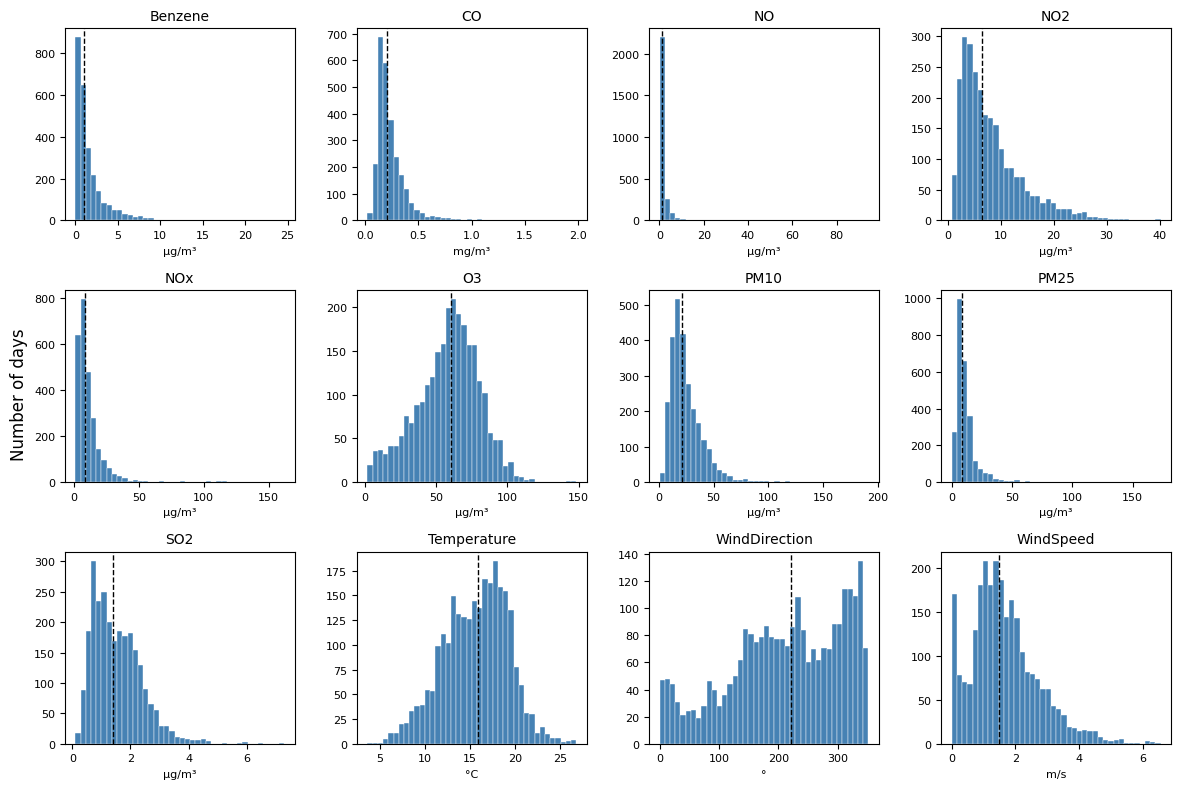

In [19]:
units = {  # check against the `unit` column in gafanha.parquet
    "Benzene": "µg/m³", "CO": "mg/m³", "NO": "µg/m³", "NO2": "µg/m³", "NOx": "µg/m³",
    "O3": "µg/m³", "PM10": "µg/m³", "PM25": "µg/m³", "SO2": "µg/m³",
    "Temperature": "°C", "WindDirection": "°", "WindSpeed": "m/s",
}
cols = [c for c in daily.columns if c != "Particles"]  # identical to PM25

def plot_hist(d, fname):
    fig, axes = plt.subplots(3, 4, figsize=(12, 8))
    for ax, c in zip(axes.flat, cols):
        s = d[c].dropna()
        ax.hist(s, bins=40, color="steelblue", edgecolor="white", linewidth=0.3)
        ax.axvline(s.median(), color="black", ls="--", lw=1)
        ax.set_title(c, fontsize=10)
        ax.set_xlabel(units[c], fontsize=8)
        ax.tick_params(labelsize=8)
    fig.supylabel("Number of days")
    plt.tight_layout()
    plt.savefig(fname, dpi=300, bbox_inches="tight")
    plt.show()

plot_hist(daily, "distributions_raw.png")

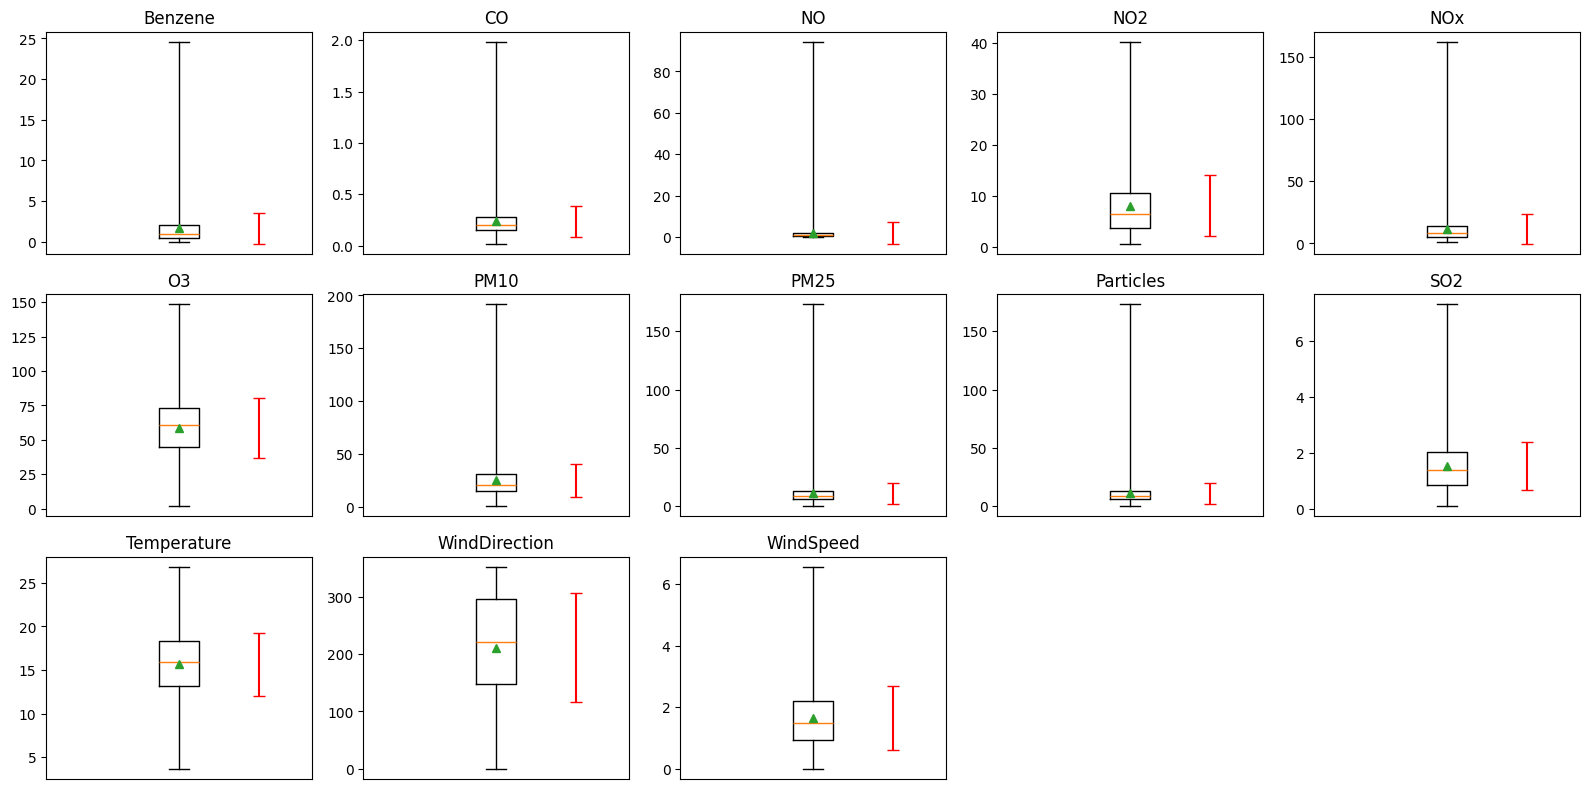

In [20]:
fig, axes = plt.subplots(3, 5, figsize=(16, 8))
for ax, c in zip(axes.flat, daily.columns):
    s = daily[c].dropna()
    ax.boxplot(s, whis=(0, 100), showmeans=True)       # whiskers = min and max
    ax.errorbar(1.3, s.mean(), yerr=s.std(), fmt="none", capsize=4, color="red")
    ax.set_title(c)
    ax.set_xticks([])
for ax in axes.flat[len(daily.columns):]:
    ax.axis("off")                                     # 13 variables, 15 slots
plt.tight_layout()
plt.show()

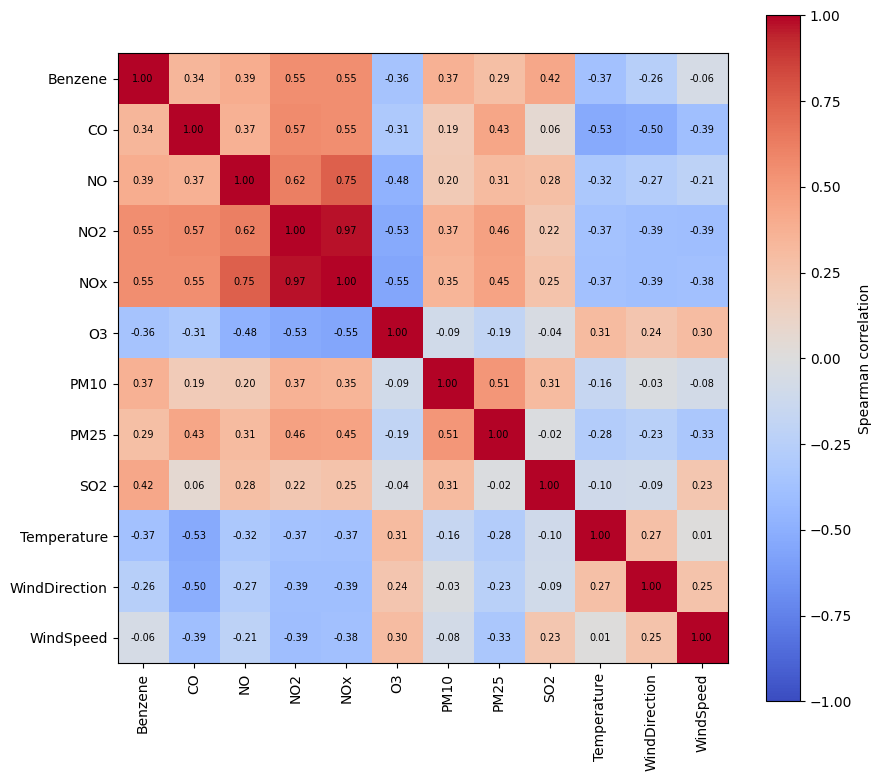

In [21]:
cols = [c for c in daily.columns if c != "Particles"]  # identical to PM25
corr = daily[cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=90)
ax.set_yticks(range(len(cols)), cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, label="Spearman correlation")
plt.tight_layout()
plt.savefig("correlation.png", dpi=300, bbox_inches="tight")
plt.show()

## **END** ##